# 01 · Exploratory data analysis
Amazon Reviews 2023, **Video_Games 5-core**, official absolute-timestamp split.

Sections 1-4 follow the proposal's *Data Preparation* bullets. Run `uv run vgrec download && uv run vgrec prepare` first.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from vgrec.analysis import history_bucket
from vgrec.config import T1_MS, T2_MS
from vgrec.data import load_dataset, load_items, load_raw_interactions, quality_report
from vgrec.protocol import make_split

ds = load_dataset()
items = load_items()
inter = ds.interactions
splits = {stage: make_split(ds, stage) for stage in ('valid', 'test')}
density = len(inter) / (ds.n_users * ds.n_items)
print(f'{ds.n_users:,} users · {ds.n_items:,} items · {len(inter):,} interactions · density {density:.2e}')

94,762 users · 25,612 items · 814,586 interactions · density 3.36e-04


## 1. Data quality: missing values, invalid ratings, duplicates, split boundaries

In [2]:
pd.Series(quality_report(load_raw_interactions()), name='count').to_frame()

,count
rows,814586
missing_values,0
invalid_rating,0
duplicate_user_item,0
split_boundary_violations,0


## 2. Sparsity and distributions

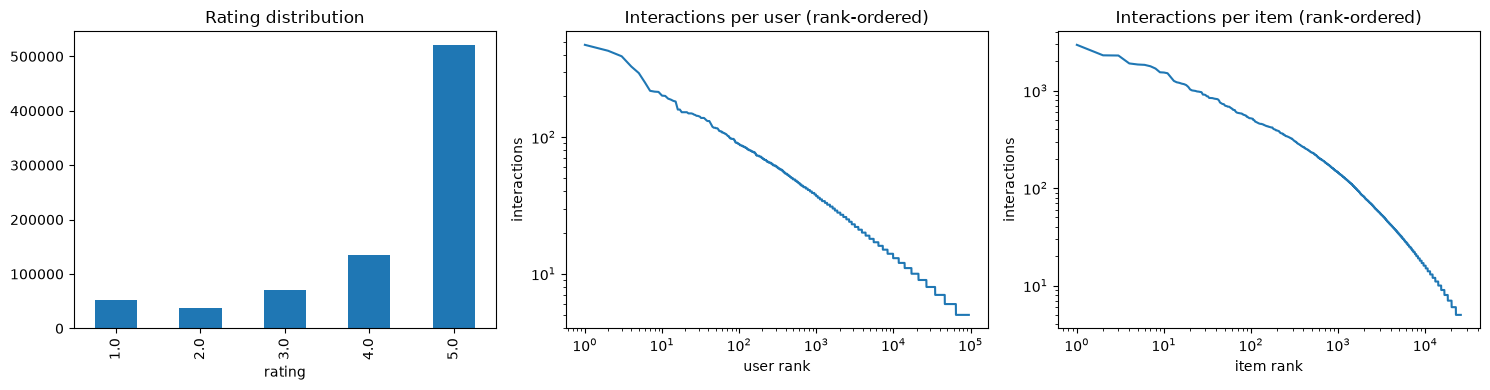

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
inter['rating'].value_counts().sort_index().plot.bar(ax=axes[0], title='Rating distribution')
for ax, col, label in [(axes[1], 'user_idx', 'user'), (axes[2], 'item_idx', 'item')]:
    counts = inter[col].value_counts().to_numpy()
    ax.loglog(np.arange(1, len(counts) + 1), counts)
    ax.set(title=f'Interactions per {label} (rank-ordered)', xlabel=f'{label} rank', ylabel='interactions')
plt.tight_layout()

In [4]:
pd.DataFrame({
    'per user': inter.groupby('user_idx').size().describe(),
    'per item': inter.groupby('item_idx').size().describe(),
}).round(1)

,per user,per item
count,94762.0,25612.0
mean,8.6,31.8
std,7.9,78.0
min,5.0,5.0
25%,5.0,7.0
50%,6.0,12.0
75%,9.0,26.0
max,473.0,2955.0


## 3. Time: split boundaries and popularity drift

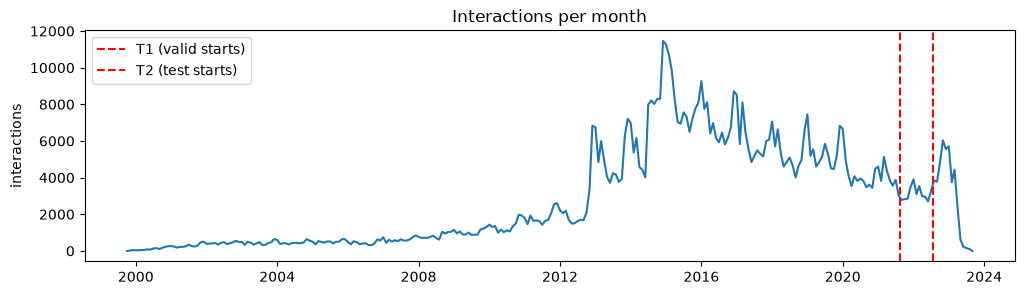

In [5]:
monthly = inter.set_index(pd.to_datetime(inter['timestamp'], unit='ms')).resample('MS').size()
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(monthly.index, monthly.to_numpy())
for t, name in ((T1_MS, 'T1 (valid starts)'), (T2_MS, 'T2 (test starts)')):
    ax.axvline(pd.to_datetime(t, unit='ms'), color='red', ls='--', label=name)
ax.set(title='Interactions per month', ylabel='interactions')
ax.legend();

In [6]:
def top_titles(split_names, n=10):
    top = inter.loc[inter['split'].isin(split_names), 'item_idx'].value_counts().head(n).index
    return items['title'].iloc[top].str.slice(0, 60).tolist()

pd.DataFrame({'train (all history)': top_titles(['train']),
              'valid period': top_titles(['valid']),
              'test period': top_titles(['test'])})

,train (all history),valid period,test period
0,amFilm Tempered Glass Screen Protector for Nin...,Meta Quest 2 — Advanced All-In-One Virtual Rea...,PlayStation DualSense Wireless Controller – Ga...
1,Skyrim VR - PlayStation 4,Pokémon Legends: Arceus - Nintendo Switch,Pokémon Scarlet - Nintendo Switch
2,Grand Theft Auto V: Premium Edition - Xbox One...,PlayStation DualSense Wireless Controller – Ga...,PlayStation 5 Console (PS5)
3,PlayStation 4 500GB Console [Old Model][Discon...,Metroid Dread: Special Edition - Nintendo Switch,"SanDisk 128GB microSDXC-Card, Licensed for Nin..."
4,Xbox Live Gold: 1 Month Membership [Digital Code],Elden Ring - PlayStation 4,Xbox Elite Wireless Controller Series 2 – Black
5,PlayStation Plus: 12 Month Membership [Digital...,"SanDisk 128GB microSDXC-Card, Licensed for Nin...",Nintendo Switch – OLED Model Splatoon 3 Specia...
6,DualShock 4 Wireless Controller for PlayStatio...,"Far Cry 6: Season Pass – Xbox Series X|S, Xbox...","PowerA Enhanced - Seafoam Fade, Gamepad, Wired..."
7,Fallout 4 - Xbox One,Xbox Elite Wireless Controller Series 2 – Black,Meta Quest 2 — Advanced All-In-One Virtual Rea...
8,Battlefield 4 - Playstation 3,Nintendo Switch – OLED Model Splatoon 3 Specia...,Turtle Beach Recon Cloud Wired Gaming Controll...
9,Assassin's Creed IV Black Flag - PC,Horizon Forbidden West Collector's Edition - P...,ivoler [4 Pack Tempered Glass Screen Protector...


## 4. Cold start under the timestamp split
Rows whose user has no history, or whose item never appears in the history, cannot be ranked by any model and are dropped from the targets.

In [7]:
pd.DataFrame({stage: split.stats for stage, split in splits.items()})

,valid,test
history_rows,736827,771337
candidate_items,22976,24070
target_rows,34510,43249
target_users,15655,13963
cold_user_rows,6404,13959
cold_item_rows,7997,10529
seen_item_rows,0,0
kept_rows,20109,18761
eval_users,11403,10049


In [8]:
pd.DataFrame({stage: pd.Series(history_bucket(split.history_lengths)).value_counts(sort=False)
              for stage, split in splits.items()})

,valid,test
1-2,1660,1250
3-4,3694,3191
5-9,3984,3729
10-19,1472,1340
20+,593,539


## 5. Item metadata completeness and text

In [9]:
fields = ['title', 'store', 'categories', 'features', 'description', 'details']
completeness = (items[fields] != '').mean().rename('share non-empty').to_frame()
words = items['item_text'].str.split().str.len().describe().rename('words per item_text')
display(completeness.round(3))
words.round(0).to_frame()

,share non-empty
title,1.000
store,0.995
categories,0.966
features,0.871
description,0.734
details,0.971


,words per item_text
count,25612.0
mean,284.0
std,320.0
min,3.0
25%,123.0
50%,205.0
75%,321.0
max,16041.0


## Observations

- **Very sparse data.** 94,762 users × 25,612 items with 814,586 interactions gives a density of 3.36 × 10⁻⁴, so 99.97% of the user-item matrix is empty. The median user has only 6 interactions and the median item 12, both with long tails (max 473 and 2,955). Collaborative models therefore have little signal per user, which motivates adding product text.
- **Clean, skewed ratings.** There are no missing values, invalid ratings, duplicate (user, item) pairs or split-boundary violations. Ratings are heavily positive: 63.8% are 5★ and only 11% are 1–2★. Stars say little about preference, so we treat every review as an implicit "interacted" signal and rank items instead of predicting stars.
- **Strong popularity drift.** The train-period top 10 (PS4/Xbox One-era titles, consoles and memberships) shares no items with the valid or test top 10 (Meta Quest 2, Pokémon, DualSense, PS5, Switch OLED). All-time popularity is therefore a poor guide to the future, which is why every learned model gets a recency (time-decay) weight.
- **Cold start is unavoidable under the timestamp split.** In the test stage, 32.3% of target rows come from users with no history and a further 24.3% are items never seen in the history. Only 43.4% of test rows (10,049 users) can be ranked by any model, so absolute scores will be small and differences need confidence intervals.
- **Short histories are common.** 44% of test users have at most 4 history interactions (1,250 have 1–2 and 3,191 have 3–4). That gives enough users per bucket to test the proposal's question of whether content helps when histories are limited.
- **Usable but incomplete metadata.** Every item has a title, and 96.6% have categories, but only 87.1% have features and 73.4% a description. The combined item text has a median of 205 words. TF-IDF still has text for every item, but items with thin metadata get weaker content vectors.